# 00. Hiểu bộ dữ liệu DAD từ con số 0

Notebook này dành cho người **chưa biết gì** về DAD. Đọc xong, bạn sẽ trả lời được:

1. Dữ liệu đo cái gì ngoài đời thật (data center, tủ làm mát, 4 loại cảm biến)?
2. Dữ liệu được tạo ra thế nào, và vì sao lại nằm trong file PCAP?
3. Repo có bao nhiêu file, mỗi file chứa gì, đọc file nào trước?
4. Một bản tin cảm biến trông thế nào bên trong (MQTT, TCP, IP)?
5. Nhãn (`label`) nghĩa là gì, và cái gì **không** được gắn nhãn?
6. Ba kiểu tấn công trông thế nào trên dữ liệu?
7. Những chỗ nào dễ hiểu nhầm?

**Lộ trình đọc:** `00` (notebook này, hiểu dataset) → `01` (EDA và thiết kế ban đầu) → `02` (data mining chi tiết, chọn bộ phát hiện, xuất cấu hình).

Mọi con số trong notebook được tính trực tiếp từ file trong repo khi chạy. Thông tin về cách tạo dữ liệu lấy từ bài báo gốc: L. Vigoya, D. Fernandez, V. Carneiro, F. Cacheda, *Annotated Dataset for Anomaly Detection in a Data Center with IoT Sensors*, Sensors 2020, 20(13), 3745.

In [1]:
import os, sys, glob, re, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from dad_loader import load_all, INROW_IP
import dad_mining as dm

RAW = os.path.abspath(os.path.join("..", ".."))
CACHE = os.path.abspath(os.path.join("..", "data", "processed"))
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; ALERT = "#e34948"; INK = "#0b0b0b"; INK2 = "#52514e"; GRID = "#c3c2b7"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
                     "axes.prop_cycle": plt.cycler(color=SERIES), "axes.edgecolor": INK2,
                     "text.color": INK, "axes.labelcolor": INK2})

## 1. Ngoài đời thật: dữ liệu đo cái gì?

**Bối cảnh.** Dữ liệu gốc đến từ data center của CITIC (Đại học A Coruña, Tây Ban Nha). Bài báo kể rằng ở đây từng xảy ra một sự cố thật: cảm biến bị cấu hình sai, gửi nhiệt độ sai tới hệ thống làm mát, máy chủ quá nhiệt, hỏng phần cứng và **cả hệ thống sập**. DAD được làm ra để luyện phát hiện kiểu sự cố này.

**Cách một phòng máy được làm mát:**
- Các tủ máy chủ (rack) xếp thành hàng. Mặt trước hút khí lạnh từ **lối lạnh** (cold aisle), mặt sau thổi khí nóng ra **lối nóng** (hot aisle).
- Xen giữa các rack là **tủ làm mát InRow**. Nó hút khí nóng từ lối nóng, cho đi qua dàn ống có **nước lạnh** chảy bên trong, rồi thổi khí đã làm mát ra lối lạnh.
- Nước lạnh đi vào tủ, nhận nhiệt từ không khí, đi ra ấm hơn rồi quay về máy làm lạnh trung tâm.

Phòng máy có 4 tủ InRow: **13, 15, 23, 25**. Mỗi tủ có 4 cảm biến nhiệt độ:

In [2]:
sensors = pd.DataFrame([
    ("TAS",  "Unit Supply Air Temperature",  "khí lạnh tủ thổi ra lối lạnh",          "≈ 20 °C"),
    ("TAR",  "Unit Return Air Temperature",  "khí nóng tủ hút vào từ lối nóng",       "≈ 26–27 °C"),
    ("TFEU", "Unit Entering Fluid Temperature", "nước lạnh đi VÀO tủ",                  "≈ 11–12 °C"),
    ("TFSU", "Unit Leaving Fluid Temperature",  "nước đi RA khỏi tủ (đã nhận nhiệt)",    "≈ 15–16 °C"),
], columns=["viết tắt", "tên đầy đủ (bài báo)", "đo cái gì", "giá trị thường gặp"])
sensors

,viết tắt,tên đầy đủ (bài báo),đo cái gì,giá trị thường gặp
0,TAS,Unit Supply Air Temperature,khí lạnh tủ thổi ra lối lạnh,≈ 20 °C
1,TAR,Unit Return Air Temperature,khí nóng tủ hút vào từ lối nóng,≈ 26–27 °C
2,TFEU,Unit Entering Fluid Temperature,nước lạnh đi VÀO tủ,≈ 11–12 °C
3,TFSU,Unit Leaving Fluid Temperature,nước đi RA khỏi tủ (đã nhận nhiệt),≈ 15–16 °C


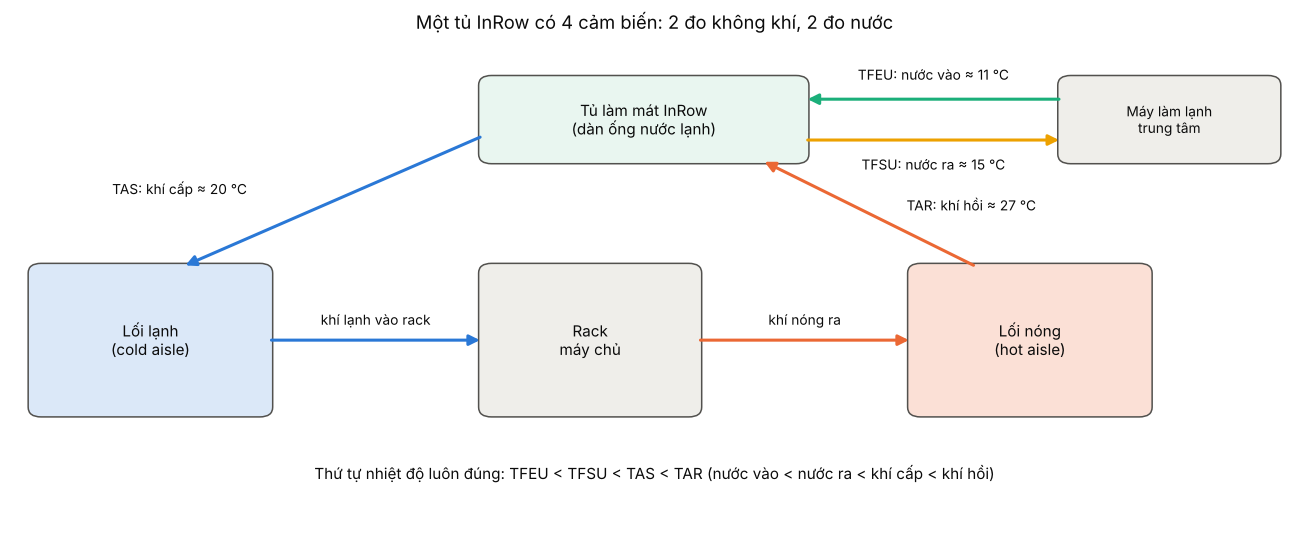

In [3]:
# Sơ đồ đơn giản: luồng khí và luồng nước qua một tủ InRow
fig, ax = plt.subplots(figsize=(12, 5)); ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.axis("off")
def box(x, y, w, h, text, fc, ec=INK2, fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec=ec, lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK)
def arrow(x1, y1, x2, y2, color):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, color=color, lw=2))
def label(x, y, text, ha="center"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=9, color=INK)
box(0.2, 1.4, 2.2, 1.8, "Lối lạnh\n(cold aisle)", "#dbe8f8")
box(4.4, 1.4, 2.0, 1.8, "Rack\nmáy chủ", "#efeeea")
box(8.4, 1.4, 2.2, 1.8, "Lối nóng\n(hot aisle)", "#fbe0d6")
box(4.4, 4.5, 3.0, 1.0, "Tủ làm mát InRow\n(dàn ống nước lạnh)", "#e9f6f0")
box(9.8, 4.5, 2.0, 1.0, "Máy làm lạnh\ntrung tâm", "#efeeea", fs=9)
arrow(2.4, 2.3, 4.4, 2.3, SERIES[0]); label(3.4, 2.55, "khí lạnh vào rack")
arrow(6.4, 2.3, 8.4, 2.3, SERIES[1]); label(7.4, 2.55, "khí nóng ra")
arrow(9.0, 3.2, 7.0, 4.5, SERIES[1]); label(8.35, 3.95, "TAR: khí hồi ≈ 27 °C", ha="left")
arrow(4.4, 4.8, 1.6, 3.2, SERIES[0]); label(2.2, 4.15, "TAS: khí cấp ≈ 20 °C", ha="right")
arrow(9.8, 5.25, 7.4, 5.25, SERIES[2]); label(8.6, 5.55, "TFEU: nước vào ≈ 11 °C")
arrow(7.4, 4.75, 9.8, 4.75, SERIES[3]); label(8.6, 4.45, "TFSU: nước ra ≈ 15 °C")
ax.text(6, 0.6, "Thứ tự nhiệt độ luôn đúng: TFEU < TFSU < TAS < TAR (nước vào < nước ra < khí cấp < khí hồi)",
        ha="center", fontsize=10, color=INK)
ax.set_title("Một tủ InRow có 4 cảm biến: 2 đo không khí, 2 đo nước", color=INK)
plt.tight_layout(); plt.show()

- **Vì sao 4 cảm biến này quan trọng:** nếu TAS báo sai (ví dụ báo thấp hơn thật), hệ thống điều khiển tưởng phòng đang mát và giảm làm lạnh, trong khi máy chủ thực ra đang nóng lên. Đúng kịch bản của sự cố thật ở CITIC.
- Thứ tự TFEU < TFSU < TAS < TAR là **quy luật vật lý**: nước nhận nhiệt nên ra ấm hơn vào, khí sau làm mát lạnh hơn khí trước làm mát. Notebook 02 dùng nó làm một quy tắc kiểm tra.

## 2. Dữ liệu được tạo ra thế nào?

DAD là dữ liệu **bán tổng hợp** (semi-synthetic): giá trị nhiệt độ được mô phỏng từ dữ liệu thật, còn lưu lượng mạng là thật nhưng chạy trong môi trường ảo.

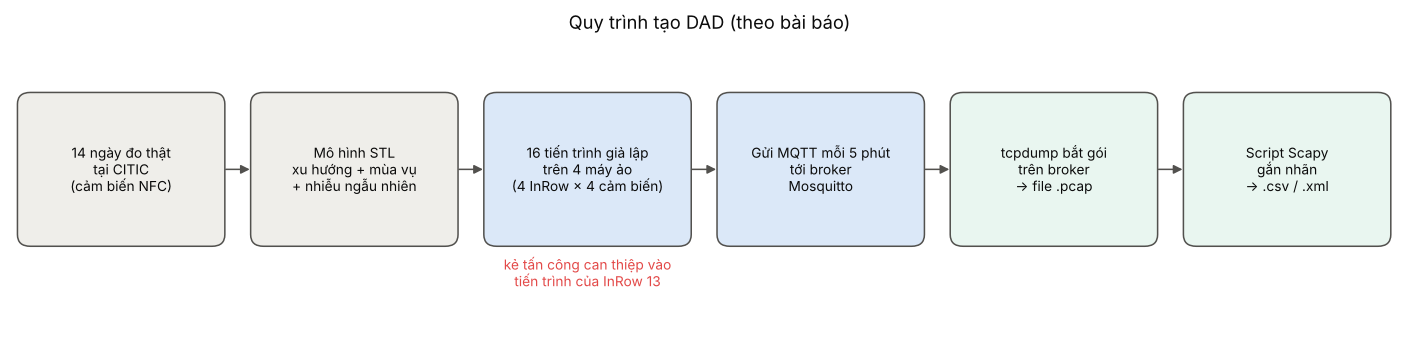

In [4]:
fig, ax = plt.subplots(figsize=(13, 3.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 3); ax.axis("off")
steps = [("14 ngày đo thật\ntại CITIC\n(cảm biến NFC)", "#efeeea"),
         ("Mô hình STL\nxu hướng + mùa vụ\n+ nhiễu ngẫu nhiên", "#efeeea"),
         ("16 tiến trình giả lập\ntrên 4 máy ảo\n(4 InRow × 4 cảm biến)", "#dbe8f8"),
         ("Gửi MQTT mỗi 5 phút\ntới broker\nMosquitto", "#dbe8f8"),
         ("tcpdump bắt gói\ntrên broker\n→ file .pcap", "#e9f6f0"),
         ("Script Scapy\ngắn nhãn\n→ .csv / .xml", "#e9f6f0")]
w, gap = 1.85, 0.32
for i, (t, fc) in enumerate(steps):
    x = 0.1 + i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 0.9), w, 1.5, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec=INK2, lw=1))
    ax.text(x + w / 2, 1.65, t, ha="center", va="center", fontsize=9, color=INK)
    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch((x + w + 0.02, 1.65), (x + w + gap - 0.02, 1.65), arrowstyle="-|>", mutation_scale=12, color=INK2))
ax.text(0.1 + 2 * (w + gap) + w / 2, 0.45, "kẻ tấn công can thiệp vào\ntiến trình của InRow 13", ha="center", fontsize=9, color=ALERT)
ax.set_title("Quy trình tạo DAD (theo bài báo)", color=INK); plt.tight_layout(); plt.show()

- **Hạ tầng ảo:** 5 máy ảo Ubuntu trên VMware. Một máy chạy broker MQTT **Mosquitto** (IP `10.6.56.1`), 4 máy còn lại mỗi máy là một tủ InRow, chạy 4 tiến trình giả lập 4 cảm biến.
- **Giá trị nhiệt độ:** tác giả thử nhiều mô hình (phân phối chuẩn, hồi quy, ARIMA) rồi chọn **STL** (tách chuỗi thành xu hướng + mùa vụ + nhiễu). Mỗi bản tin = xu hướng + mùa vụ + một số ngẫu nhiên.
- **Vì sao dữ liệu nằm trong PCAP chứ không phải bảng nhiệt độ:** DAD được làm cho bài toán **phát hiện bất thường trên lưu lượng mạng IoT**. Nhiệt độ nằm bên trong payload của từng bản tin MQTT; muốn có bảng nhiệt độ thì phải tự giải mã PCAP (`src/dad_loader.py` làm việc này).
- **Tấn công:** chỉ xảy ra ở tiến trình của **InRow 13 (IP `10.6.56.41`)**, theo lịch định sẵn trong tuần (mục 9).

## 3. Repo có những file gì?

Mỗi ngày trong tuần (21–27/10/2019) có **3 file**. Tên file có dạng `capture_YYMMDDhhmm_<thứ>.pcap`, ví dụ `capture_1910230000_wed.pcap` là ngày 23/10/2019 từ 00:00, thứ Tư.

In [5]:
rows = []
for f in sorted(glob.glob(os.path.join(RAW, "capture_*"))):
    name = os.path.basename(f); ext = name.rsplit(".", 1)[1]
    stamp = re.search(r"capture_(\d{10})", name).group(1)
    rows.append(dict(file=name, ngày=pd.to_datetime(stamp, format="%y%m%d%H%M").strftime("%a %d/%m"), loại=ext, KB=round(os.path.getsize(f) / 1024)))
inv = pd.DataFrame(rows)
print(inv.groupby("loại").agg(số_file=("file", "size"), tổng_KB=("KB", "sum")))
inv["thứ tự"] = inv.file.str.extract(r"capture_(\d{10})")[0]
inv.pivot_table(index=["thứ tự", "ngày"], columns="loại", values="file", aggfunc="first").droplevel(0)

      số_file  tổng_KB
loại                  
csv         7     2708
pcap        7     8786
xml         7     6671


loại,csv,pcap,xml
ngày,,,
Mon 21/10,capture_1910210000_labels.csv,capture_1910210000_mon.pcap,capture_1910210000_labels.xml
Tue 22/10,capture_1910220000_labels.csv,capture_1910220000_tue.pcap,capture_1910220000_labels.xml
Wed 23/10,capture_1910230000_labels.csv,capture_1910230000_wed.pcap,capture_1910230000_labels.xml
Thu 24/10,capture_1910240000_labels.csv,capture_1910240000_thu.pcap,capture_1910240000_labels.xml
Fri 25/10,capture_1910250000_labels.csv,capture_1910250000_fri.pcap,capture_1910250000_labels.xml
Sat 26/10,capture_1910260000_labels.csv,capture_1910260000_sat.pcap,capture_1910260000_labels.xml
Sun 27/10,capture_1910270000_labels.csv,capture_1910270000_sun.pcap,capture_1910270000_labels.xml


In [6]:
# File .xml có gì? So với .csv của cùng ngày
import xml.etree.ElementTree as ET
day_file = "capture_1910230000"
xml = pd.DataFrame([{c.tag: c.text for c in p} for p in ET.fromstring("<r>" + open(os.path.join(RAW, day_file + "_labels.xml")).read().split("?>", 1)[1] + "</r>")])
csv = pd.read_csv(os.path.join(RAW, day_file + "_labels.csv"), sep=";")
print("Cột trong XML:", list(xml.columns), "| số dòng", len(xml))
print("Cột trong CSV:", list(csv.columns), "| số dòng", len(csv))
print("Nhãn XML trùng hoàn toàn nhãn CSV:", (xml["label"].astype(int).values == csv["label"].values).all())

Cột trong XML: ['frame.number', 'label'] | số dòng 14524
Cột trong CSV: ['frame.number', 'ip.src', 'tcp.srcport', 'mqtt.clientid', 'mqtt.msgid', 'label'] | số dòng 14524
Nhãn XML trùng hoàn toàn nhãn CSV: True


| Loại file | Có mấy file | Chứa gì | Cần dùng không |
|---|---|---|---|
| `.pcap` | 7 | **Toàn bộ gói tin mạng** bắt được trên broker trong 1 ngày (khoảng 14.500 gói/ngày). Nhiệt độ nằm trong đây. Mở bằng Wireshark hoặc Python `scapy` | **Có**, đây là dữ liệu chính |
| `_labels.csv` | 7 | Mỗi gói tin một dòng: số thứ tự frame, IP và cổng nguồn, `clientId` và `msgid` (nếu là bản tin PUBLISH), **nhãn** 0/1 | **Có**, để biết bản tin nào bị tấn công |
| `_labels.xml` | 7 | Chỉ có số frame và nhãn, **trùng hoàn toàn** với CSV (ô trên) | Không, bỏ qua được |
| `README.md` | 1 | Mô tả ngắn và lịch tấn công | Đọc một lần |

**Cách ghép:** dòng thứ *n* trong CSV ứng với gói thứ *n* trong PCAP cùng ngày (`frame.number`). Ghép theo cặp **(ngày, frame.number)**.

## 4. Bên trong một bản tin: MQTT trong 5 phút

**MQTT** là giao thức nhắn tin nhẹ, rất phổ biến cho IoT, theo mô hình **publish/subscribe**: thiết bị *publish* (gửi) bản tin lên một **broker** trung tâm, kèm một **topic** (chủ đề); ai cần dữ liệu thì *subscribe* topic đó ở broker. Thiết bị không nói chuyện trực tiếp với nhau.

Trong DAD, mỗi cảm biến là một **MQTT client** riêng. Một ngày của một cảm biến diễn ra thế này:

In [7]:
net = dm.parse_network(RAW, os.path.join(CACHE, "network.pkl"))
mtype_name = {1: "CONNECT", 2: "CONNACK", 3: "PUBLISH", 4: "PUBACK", 14: "DISCONNECT"}
conn131 = net[(net.day == "mon") & (net.client_id == "131")].conn.iloc[0]          # kết nối của cảm biến 131 hôm thứ Hai
s = net[(net.day == "mon") & (net.conn == conn131) & net.mtype.notna()].head(7)
s.assign(giờ=s.time.dt.strftime("%H:%M:%S.%f").str[:-3], chiều=np.where(s.dport == 1883, "cảm biến → broker", "broker → cảm biến"),
         loại=s.mtype.map(mtype_name)).assign(msgid=s.msgid.astype("Int64"))[["frame", "giờ", "chiều", "loại", "client_id", "msgid", "payload"]].astype(str).replace({"nan": "", "<NA>": ""})

,frame,giờ,chiều,loại,client_id,msgid,payload
124,125,00:00:02.607,cảm biến → broker,CONNECT,131,NaN,NaN
132,133,00:00:02.607,broker → cảm biến,CONNACK,NaN,NaN,NaN
142,143,00:00:02.608,cảm biến → broker,PUBLISH,NaN,1,12.12
143,144,00:00:02.608,broker → cảm biến,PUBACK,NaN,1,NaN
198,199,00:05:02.709,cảm biến → broker,PUBLISH,NaN,2,12.12
199,200,00:05:02.709,broker → cảm biến,PUBACK,NaN,2,NaN
248,249,00:10:02.811,cảm biến → broker,PUBLISH,NaN,3,12.31


| Loại bản tin | Ai gửi | Ý nghĩa |
|---|---|---|
| `CONNECT` | cảm biến | "Tôi là client `131`, cho tôi kết nối". Đây là **chỗ duy nhất** có `clientId` |
| `CONNACK` | broker | "Đồng ý kết nối" |
| `PUBLISH` | cảm biến | **Bản tin dữ liệu**: topic `IoT`, payload là nhiệt độ dạng chữ (ví dụ `"12.12"`), kèm `msgid` tăng dần |
| `PUBACK` | broker | "Đã nhận bản tin `msgid` này". Có vì DAD dùng **QoS 1** (đảm bảo nhận ít nhất một lần) |
| `DISCONNECT` | cảm biến | Ngắt kết nối (mỗi ngày một lần, lúc chuyển ngày) |

Như vậy **mỗi giá trị nhiệt độ sinh ra 2 bản tin MQTT** (PUBLISH và PUBACK), cộng thêm vài gói TCP ACK. Mỗi cảm biến gửi **mỗi 5 phút**, tức 288 lần/ngày; 16 cảm biến cho khoảng 4.608 PUBLISH/ngày.

In [8]:
# "Mổ xẻ" một gói PUBLISH: các lớp giao thức lồng nhau
from scapy.all import rdpcap, IP, TCP
from scapy.contrib.mqtt import MQTT, MQTTPublish
pk = next(p for p in rdpcap(os.path.join(RAW, "capture_1910210000_mon.pcap"), count=200) if p.haslayer(MQTTPublish))
m, pub = pk[MQTT], pk[MQTTPublish]
pd.DataFrame([
    ("IP", "src", pk[IP].src, "địa chỉ máy gửi = một tủ InRow"),
    ("IP", "dst", pk[IP].dst, "broker MQTT"),
    ("TCP", "sport", pk[TCP].sport, "cổng nguồn: mỗi cảm biến một cổng, đổi mỗi ngày"),
    ("TCP", "dport", pk[TCP].dport, "1883 = cổng chuẩn của MQTT"),
    ("TCP", "flags", str(pk[TCP].flags), "PA = có dữ liệu (Push) + xác nhận (Ack)"),
    ("MQTT", "type", m.type, "3 = PUBLISH"),
    ("MQTT", "QOS", m.QOS, "1 = broker phải trả PUBACK"),
    ("MQTT", "DUP", m.DUP, "0 = không phải gửi lại"),
    ("MQTT", "topic", pub.topic.decode(), "mọi cảm biến dùng chung topic 'IoT'"),
    ("MQTT", "msgid", pub.msgid, "số thứ tự bản tin trong kết nối"),
    ("MQTT", "value", pub.value.decode(), "NHIỆT ĐỘ (°C), dạng chữ"),
], columns=["lớp", "trường", "giá trị", "ý nghĩa"])

,lớp,trường,giá trị,ý nghĩa
0,IP,src,10.6.56.36,địa chỉ máy gửi = một tủ InRow
1,IP,dst,10.6.56.1,broker MQTT
2,TCP,sport,47590,"cổng nguồn: mỗi cảm biến một cổng, đổi mỗi ngày"
3,TCP,dport,1883,1883 = cổng chuẩn của MQTT
4,TCP,flags,PA,PA = có dữ liệu (Push) + xác nhận (Ack)
5,MQTT,type,3,3 = PUBLISH
6,MQTT,QOS,1,1 = broker phải trả PUBACK
7,MQTT,DUP,0,0 = không phải gửi lại
8,MQTT,topic,IoT,mọi cảm biến dùng chung topic 'IoT'
9,MQTT,msgid,1,số thứ tự bản tin trong kết nối


Lưu ý: bản tin PUBLISH **không chứa `clientId`**. Muốn biết nhiệt độ của cảm biến nào, phải nhớ cảm biến nào đã `CONNECT` qua cặp (IP, cổng) đó. `dad_loader.py` làm việc này.

## 5. Ngoài MQTT, PCAP còn những gói gì?

In [9]:
kind = np.select(
    [net.mtype.eq(3), net.mtype.eq(4), net.mtype.isin([1, 2, 14]),
     net.proto.eq("TCP") & net.mtype.isna() & net.tcp_flags.eq("A"),
     net.proto.eq("TCP") & net.mtype.isna(), net.dport.eq(123), net.dport.eq(137)],
    ["MQTT PUBLISH", "MQTT PUBACK", "MQTT CONNECT/CONNACK/DISCONNECT", "TCP ACK thuần", "TCP mở/đóng kết nối (SYN, FIN, RST)",
     "NTP (đồng bộ giờ, UDP 123)", "NetBIOS (UDP 137)"], "khác")
mix = pd.Series(kind).value_counts().rename("số gói").to_frame()
mix["tỷ lệ"] = (mix["số gói"] / len(net) * 100).round(1).astype(str) + "%"
mix["ý nghĩa"] = mix.index.map({
    "MQTT PUBLISH": "bản tin nhiệt độ",
    "MQTT PUBACK": "broker xác nhận đã nhận",
    "TCP ACK thuần": "TCP xác nhận đã nhận gói (không có dữ liệu)",
    "MQTT CONNECT/CONNACK/DISCONNECT": "bắt đầu và kết thúc phiên, mỗi ngày một lần",
    "TCP mở/đóng kết nối (SYN, FIN, RST)": "mở/đóng kết nối TCP lúc chuyển ngày",
    "NTP (đồng bộ giờ, UDP 123)": "máy ảo đồng bộ giờ với broker",
    "NetBIOS (UDP 137)": "broadcast của hệ điều hành, không liên quan",
})
mix

,số gói,tỷ lệ,ý nghĩa
TCP ACK thuần,32700,32.2%,TCP xác nhận đã nhận gói (không có dữ liệu)
MQTT PUBLISH,32288,31.8%,bản tin nhiệt độ
MQTT PUBACK,32268,31.8%,broker xác nhận đã nhận
"NTP (đồng bộ giờ, UDP 123)",3438,3.4%,máy ảo đồng bộ giờ với broker
"TCP mở/đóng kết nối (SYN, FIN, RST)",570,0.6%,mở/đóng kết nối TCP lúc chuyển ngày
MQTT CONNECT/CONNACK/DISCONNECT,316,0.3%,"bắt đầu và kết thúc phiên, mỗi ngày một lần"
NetBIOS (UDP 137),3,0.0%,"broadcast của hệ điều hành, không liên quan"


- Tổng **101.583 gói**, nhưng phần mang thông tin nhiệt độ chỉ là **32.288 PUBLISH** (32%). Phần còn lại là "giấy tờ" của giao thức: xác nhận, mở/đóng kết nối, đồng bộ giờ.
- Node `10.6.56.34` (InRow 25) không có gói NTP trong capture vì nó đồng bộ giờ qua **card mạng thứ hai** (theo bài báo), không phải vì mất đồng bộ.
- **Mọi tấn công đều nằm trong bản tin PUBLISH.** Các loại gói khác đều bình thường.

## 6. File nhãn CSV: từng cột nghĩa là gì

In [10]:
lab = pd.concat([pd.read_csv(f, sep=";").assign(day=d) for d, f in zip(dm.DAYS, sorted(glob.glob(os.path.join(RAW, "*_labels.csv"))))])
print("Tổng số dòng:", len(lab), "= tổng số gói trong 7 file PCAP")
ex = pd.concat([lab[(lab["ip.src"] == "10.6.56.1")].head(1), lab[lab["mqtt.clientid"].isna() & (lab["ip.src"] != "10.6.56.1")].head(1),
                lab[lab["mqtt.clientid"].notna() & (lab.label == 0)].head(1), lab[lab.label == 1].head(1)])
ex.insert(0, "loại dòng", ["gói của broker", "gói của cảm biến, không phải PUBLISH", "PUBLISH bình thường", "PUBLISH bị tấn công"])
ex

Tổng số dòng: 101583 = tổng số gói trong 7 file PCAP


,loại dòng,frame.number,ip.src,tcp.srcport,mqtt.clientid,mqtt.msgid,label,day
1,gói của broker,2,10.6.56.1,1883.0,NaN,NaN,0,mon
0,"gói của cảm biến, không phải PUBLISH",1,10.6.56.36,47590.0,NaN,NaN,0,mon
60,PUBLISH bình thường,61,10.6.56.36,47590.0,152.0,1.0,0,mon
2706,PUBLISH bị tấn công,2707,10.6.56.41,49152.0,133.0,51.0,1,wed


| Cột | Ý nghĩa | Khi nào có giá trị |
|---|---|---|
| `frame.number` | số thứ tự gói trong file PCAP **cùng ngày**, bắt đầu từ 1 | mọi dòng |
| `ip.src` | IP máy gửi: `10.6.56.1` là broker, 4 IP còn lại là 4 tủ InRow | mọi dòng |
| `tcp.srcport` | cổng TCP nguồn (`1883` nếu broker gửi) | gói TCP |
| `mqtt.clientid` | mã cảm biến, ví dụ `131` | **chỉ dòng PUBLISH** |
| `mqtt.msgid` | số thứ tự bản tin trong kết nối | **chỉ dòng PUBLISH** |
| `label` | `1` = bản tin bị can thiệp, `0` = bình thường | mọi dòng |

In [11]:
pub_rows = lab["mqtt.clientid"].notna()
print("Dòng PUBLISH:", int(pub_rows.sum()), "| dòng nhãn 1:", int(lab.label.sum()),
      "| nhãn 1 nằm trên PUBLISH:", int((pub_rows & (lab.label == 1)).sum()))
print("Nhãn 1 theo ngày:", lab[lab.label == 1].groupby("day").size().to_dict())
print("Nhãn 1 theo cảm biến:", lab[lab.label == 1]["mqtt.clientid"].astype(int).value_counts().sort_index().to_dict())

Dòng PUBLISH: 32288 | dòng nhãn 1: 544 | nhãn 1 nằm trên PUBLISH: 544
Nhãn 1 theo ngày: {'fri': 192, 'sat': 192, 'thu': 56, 'wed': 104}
Nhãn 1 theo cảm biến: {131: 136, 132: 136, 133: 136, 134: 136}


**Ba điều phải nhớ về nhãn**
1. Chỉ **544 bản tin PUBLISH** có nhãn 1, đều của InRow 13 (`131`–`134`). Bài báo ghi "1.088 packet bất thường" vì đếm cả PUBACK đi kèm: 1.088 = 2 × 544.
2. **Interception (chặn gói) không có nhãn**, vì gói bị chặn đã biến mất khỏi PCAP; không có dòng nào để gắn nhãn. Muốn biết chỗ bị chặn phải tìm **khoảng trống** trong nhịp gửi.
3. Nhãn đánh dấu "bản tin của cảm biến **đang bị can thiệp**", không nói bản tin đó bị sửa thế nào.

## 7. Từ điển định danh: IP, InRow, clientId, cổng

In [12]:
ids = pd.DataFrame([(ip, r) for ip, r in INROW_IP.items()], columns=["IP", "InRow"]).sort_values("InRow")
ids["clientId"] = ids.InRow.map(lambda r: f"{r}1, {r}2, {r}3, {r}4")
ids["bị tấn công?"] = np.where(ids.InRow == 13, "CÓ (mọi tấn công)", "không")
ids

,IP,InRow,clientId,bị tấn công?
0,10.6.56.41,13,"131, 132, 133, 134",CÓ (mọi tấn công)
1,10.6.56.36,15,"151, 152, 153, 154",không
2,10.6.56.50,23,"231, 232, 233, 234",không
3,10.6.56.34,25,"251, 252, 253, 254",không


In [13]:
c = net[net.mtype == 1]
ports = c[c.client_id.str.startswith("13")].pivot_table(index="client_id", columns="day", values="sport", aggfunc="first")[dm.DAYS]
print("Cổng TCP của 4 cảm biến InRow 13 theo ngày (đổi mỗi ngày):"); ports.astype(int)

Cổng TCP của 4 cảm biến InRow 13 theo ngày (đổi mỗi ngày):


day,mon,tue,wed,thu,fri,sat,sun
client_id,,,,,,,
131,49134,49146,49150,49158,49166,49174,49182
132,49140,49144,49154,49160,49168,49180,49186
133,49136,49142,49152,49162,49170,49176,49184
134,49138,49148,49156,49164,49172,49178,49188


- **`clientId` = số InRow + một chữ số vị trí (1–4).** Ví dụ `153` là cảm biến số 3 của InRow 15.
- **Chữ số vị trí ứng với loại cảm biến nào?** Bài báo **không nhất quán**: phần chữ liệt kê theo thứ tự TAS, TAR, TFEU, TFSU, còn Hình 1 đánh số 3 = TAR, 4 = TAS. Xác định theo **giá trị đo** thì rõ ràng: `x1` ≈ 11–12 °C (**TFEU**), `x2` ≈ 15–16 (**TFSU**), `x3` ≈ 20 (**TAS**), `x4` ≈ 27 (**TAR**). Toàn bộ repo dùng ánh xạ theo giá trị này.
- Mỗi cảm biến mở **một kết nối TCP mỗi ngày** với một cổng mới (bảng trên): 16 cảm biến × 7 ngày = 112 kết nối.

## 8. Sau khi giải mã: bảng telemetry

`load_all()` trong `src/dad_loader.py` đọc 7 PCAP, ghép nhãn và trả về bảng `pubs`: **mỗi dòng là một bản tin nhiệt độ**. Đây là bảng mà notebook 01 và 02 dùng.

In [14]:
packets, pubs = load_all(RAW, CACHE)
pubs = dm.add_baseline(pubs)   # thêm new_conn (bản tin đầu của kết nối mới), baseline, dev
print("Số bản tin:", len(pubs), "| số cảm biến:", pubs.client_id.nunique(), "| từ", pubs.time.min(), "đến", pubs.time.max())
pubs[["day", "frame", "time", "src", "sport", "client_id", "inrow", "sensor", "msgid", "value", "gap_s", "label"]].head(5)

Số bản tin: 32288 | số cảm biến: 16 | từ 2019-10-21 00:00:02.550414085+02:00 đến 2019-10-27 22:55:31.655834913+01:00


,day,frame,time,src,sport,client_id,inrow,sensor,msgid,value,gap_s,label
0,mon,143,2019-10-21 00:00:02.608530998+02:00,10.6.56.41,49134,131,13,TFEU,1,12.12,NaN,0
1,mon,199,2019-10-21 00:05:02.709629059+02:00,10.6.56.41,49134,131,13,TFEU,2,12.12,300.101098,0
2,mon,249,2019-10-21 00:10:02.811069965+02:00,10.6.56.41,49134,131,13,TFEU,3,12.31,300.101441,0
3,mon,297,2019-10-21 00:15:02.912472010+02:00,10.6.56.41,49134,131,13,TFEU,4,12.13,300.101402,0
4,mon,349,2019-10-21 00:20:03.013988018+02:00,10.6.56.41,49134,131,13,TFEU,5,12.33,300.101516,0


| Cột | Ý nghĩa |
|---|---|
| `day` | ngày (`mon` … `sun`), theo tên file PCAP |
| `frame` | số thứ tự gói trong PCAP, dùng để ghép nhãn |
| `ts`, `time_utc`, `time` | thời điểm broker nhận: số giây Unix, giờ UTC, giờ Tây Ban Nha |
| `src`, `sport` | IP và cổng của tủ InRow gửi |
| `client_id` | mã cảm biến (từ gói CONNECT) |
| `inrow`, `sensor` | số tủ và loại cảm biến (suy từ `client_id`) |
| `msgid` | số thứ tự bản tin trong kết nối |
| `value` | **nhiệt độ (°C)** |
| `gap_s` | số giây kể từ bản tin trước của **cùng cảm biến**. Bình thường ≈ 300 |
| `label` | nhãn 0/1 từ CSV |

In [15]:
cnt = pubs.groupby(["day", "inrow"], observed=True).size().unstack()
cnt.index = cnt.index.astype(str); print("Số bản tin theo ngày × InRow (bình thường = 4 cảm biến × 288 = 1.152):"); cnt

Số bản tin theo ngày × InRow (bình thường = 4 cảm biến × 288 = 1.152):


inrow,13,15,23,25
day,,,,
mon,1152,1152,1152,1152
tue,1112,1152,1152,1152
wed,1152,1152,1152,1152
thu,1152,1152,1152,1152
fri,1168,1152,1152,1152
sat,1192,1152,1152,1152
sun,1156,1156,1156,1156


- Ngày bình thường: đúng **1.152** bản tin mỗi InRow. InRow 13 thiếu ở thứ Ba (bị chặn), thừa ở thứ Sáu và thứ Bảy (bị chèn nhiều hơn bị chặn).
- Chủ nhật mọi InRow có **1.156** (thừa 4): đó là 4 bản tin của **phiên hôm trước** gửi ngay sau 00:00, trước khi cảm biến kết nối lại. Không phải tấn công.

## 9. Một tuần nhìn từ trên cao

Lịch tấn công theo README và bài báo, đặt cạnh những gì thấy được trong dữ liệu (InRow 13):

In [16]:
r13 = pubs[pubs.inrow == 13]
sched = pd.DataFrame({
    "README/bài báo": ["không tấn công", "xoá một số gói (không gắn nhãn)", "sửa giá trị 4h–6h", "chèn gói < 5 phút lúc 3h",
                       "trộn cả 3 loại lúc 6h và 14–16h", "trộn cả 3 loại lúc 6h và 14–16h", "không tấn công"],
    "bản tin có nhãn": r13.groupby("day", observed=True).label.sum().astype(int).values,
    "khoảng trống > 7,5 phút": r13[r13.gap_s > 450].groupby("day", observed=True).size().reindex(dm.DAYS, fill_value=0).values,
    "bản tin đến sớm < 4 phút": r13[(r13.gap_s < 240) & ~r13.new_conn].groupby("day", observed=True).size().reindex(dm.DAYS, fill_value=0).values,
}, index=["T2 21/10", "T3 22/10", "T4 23/10", "T5 24/10", "T6 25/10", "T7 26/10", "CN 27/10"])
sched

,README/bài báo,bản tin có nhãn,"khoảng trống > 7,5 phút",bản tin đến sớm < 4 phút
T2 21/10,không tấn công,0,0,0
T3 22/10,xoá một số gói (không gắn nhãn),0,20,0
T4 23/10,sửa giá trị 4h–6h,104,0,0
T5 24/10,chèn gói < 5 phút lúc 3h,56,0,56
T6 25/10,trộn cả 3 loại lúc 6h và 14–16h,192,20,96
T7 26/10,trộn cả 3 loại lúc 6h và 14–16h,192,24,96
CN 27/10,không tấn công,0,0,0


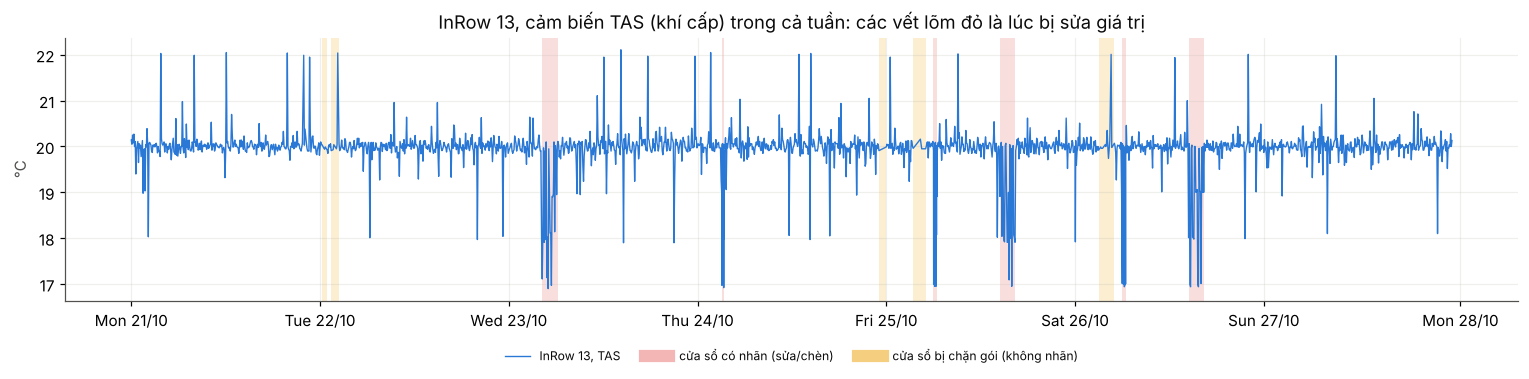

In [17]:
fig, ax = plt.subplots(figsize=(14, 3.6))
g = r13[r13.sensor == "TAS"]
ax.plot(g.time, g.value, color=SERIES[0], lw=0.9, label="InRow 13, TAS")
for _, w in dm.ground_truth(pubs).iterrows():
    ax.axvspan(w.start, w.end, color=ALERT if w.kind == "labeled" else SERIES[3], alpha=0.18, lw=0)
ax.plot([], [], color=ALERT, alpha=0.4, lw=8, label="cửa sổ có nhãn (sửa/chèn)")
ax.plot([], [], color=SERIES[3], alpha=0.5, lw=8, label="cửa sổ bị chặn gói (không nhãn)")
ax.set_ylabel("°C"); ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False)
ax.set_title("InRow 13, cảm biến TAS (khí cấp) trong cả tuần: các vết lõm đỏ là lúc bị sửa giá trị")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=r13.time.dt.tz)); plt.tight_layout(); plt.show()

## 10. Ba kiểu tấn công trông thế nào

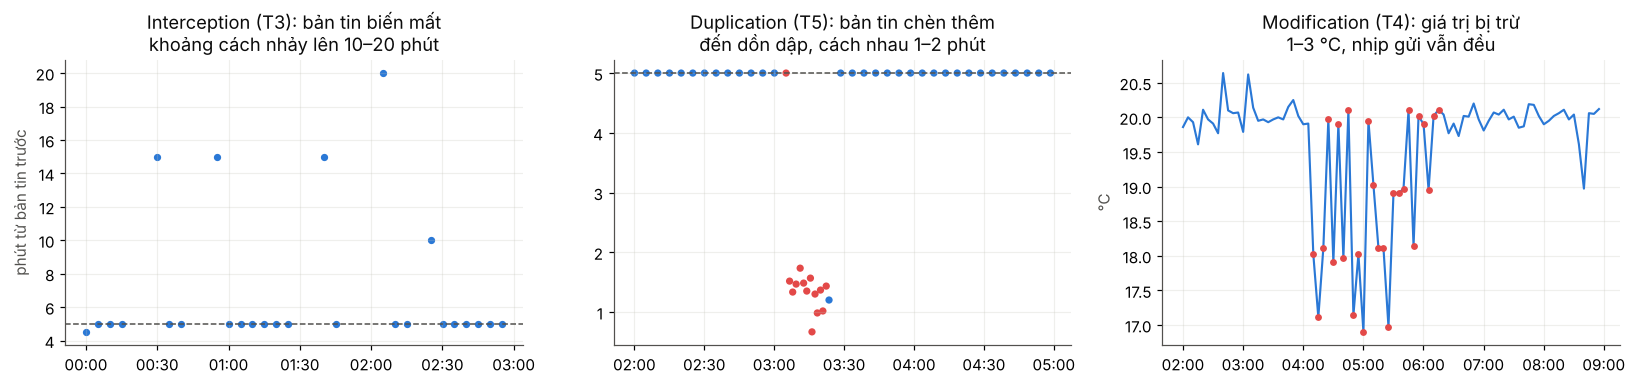

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
def window(day, h0, h1):
    d = r13[(r13.day == day) & (r13.sensor == "TAS")]
    return d[(d.time.dt.hour >= h0) & (d.time.dt.hour < h1)]
d = window("tue", 0, 3); axes[0].scatter(d.time, d.gap_s / 60, s=14, color=SERIES[0])
axes[0].axhline(5, color=INK2, ls="--", lw=1); axes[0].set_ylabel("phút từ bản tin trước")
axes[0].set_title("Interception (T3): bản tin biến mất\nkhoảng cách nhảy lên 10–20 phút")
d = window("thu", 2, 5); axes[1].scatter(d.time, d.gap_s / 60, s=14, color=[ALERT if l else SERIES[0] for l in d.label])
axes[1].axhline(5, color=INK2, ls="--", lw=1); axes[1].set_title("Duplication (T5): bản tin chèn thêm\nđến dồn dập, cách nhau 1–2 phút")
d = window("wed", 2, 9); axes[2].plot(d.time, d.value, color=SERIES[0]); dl = d[d.label == 1]
axes[2].scatter(dl.time, dl.value, s=12, color=ALERT, zorder=3); axes[2].set_ylabel("°C")
axes[2].set_title("Modification (T4): giá trị bị trừ\n1–3 °C, nhịp gửi vẫn đều")
for a in axes: a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=r13.time.dt.tz))
plt.tight_layout(); plt.show()

| Kiểu | Kẻ tấn công làm gì (bài báo) | Thấy trên dữ liệu ra sao | Có nhãn? |
|---|---|---|---|
| **Interception** (chặn) | xoá ngẫu nhiên một số bản tin | khoảng cách giữa 2 bản tin > 5 phút (thường 10–20 phút) | **không** |
| **Duplication** (chèn) | rút ngắn thời gian chờ, gửi nhiều hơn kế hoạch | bản tin đến cách nhau 40–104 giây | có |
| **Modification** (sửa) | đổi giá trị nhiệt độ | cả 4 cảm biến cùng bị **trừ một số nguyên 0–3 °C**, nhịp gửi không đổi | có |

Trong hình giữa, chấm xanh ở khoảng 1,2 phút là bản tin **bình thường** đầu tiên sau đợt chèn: nó đến sớm vì lịch gửi của cảm biến bị lệch pha. Còn bản tin bị chèn đầu tiên (chấm đỏ ở mức 5 phút) lại đến đúng nhịp.

Cả ba kiểu đều **tác động cùng lúc lên cả 4 cảm biến** của InRow 13. Đây là tấn công vào cả tủ (node), không phải hỏng một cảm biến lẻ.

## 11. Những chỗ dễ hiểu nhầm

| Dễ nghĩ là | Thực ra |
|---|---|
| Có 1.088 bản tin bất thường | **544** bản tin PUBLISH; 1.088 là đếm cả PUBACK |
| Nhãn bao phủ mọi tấn công | Interception **không có nhãn** (gói đã bị xoá) |
| File nhãn chỉ có dòng PUBLISH | CSV có **mọi gói**; `clientid`/`msgid` chỉ điền ở dòng PUBLISH |
| `msgid` nhảy cóc khi mất gói | **Không**: `msgid` luôn tăng đều 1, kể cả khi bị chặn. Chỉ phát hiện mất gói bằng **thời gian** |
| Có thể đọc nhiệt độ từ CSV | **Không**: nhiệt độ chỉ có trong payload của PCAP |
| Chữ số cuối `clientId` khớp Hình 1 của bài báo | Hình 1 ghi 3 = TAR, 4 = TAS; giá trị đo cho thấy **3 = TAS, 4 = TAR** |
| File mỗi ngày bắt đầu đúng 00:00 UTC | File chia theo **giờ Tây Ban Nha** (UTC+2, ngày 27/10 đổi giờ mùa đông). Nên xử lý theo UTC |
| Kết nối của ngày nào nằm gọn trong file ngày đó | Kết nối đóng vào **đầu ngày hôm sau**, nên vài gói đầu file thuộc phiên hôm trước |
| `keepalive` khác nhau giữa các ngày là dấu hiệu tấn công | Đó là cấu hình của **quy trình sinh dữ liệu** (đổi cho các ngày có interception, áp lên mọi node). Dùng làm bộ phát hiện là "học vẹt" quy trình |
| Dữ liệu giống dữ liệu thật | Trung bình khớp, nhưng **dao động và tương quan giữa cảm biến bị giản lược** (notebook 02, mục 7.2) |

## 12. Thuật ngữ dùng trong notebook 01 và 02

| Thuật ngữ | Nghĩa |
|---|---|
| **Chu kỳ (P)** | khoảng cách chuẩn giữa 2 bản tin của một cảm biến: 300,1 giây |
| **Slot** | ô thời gian 5 phút; gom 4 cảm biến của một InRow vào cùng một slot |
| **Baseline** | mức "bình thường" của một cảm biến, ở đây là trung vị của 288 bản tin trước đó (1 ngày). Chỉ dùng quá khứ |
| **dev (độ lệch)** | giá trị hiện tại trừ baseline |
| **Cửa sổ sự cố (ground truth)** | khoảng thời gian liên tục có tấn công; DAD có 11 cửa sổ |
| **Flow** | trong bài báo: chuỗi gói cùng chiều, cùng (IP, cổng) nguồn và đích, ngắt khi im lặng quá 30 giây |
| **D1, D2, D4** | 3 quy tắc phát hiện ở notebook 02: im lặng quá lâu, gửi dồn, giá trị thấp hơn baseline nhiều chu kỳ |
| **Báo giả** | cảnh báo khi không có tấn công |
| **Độ trễ phát hiện** | thời gian từ lúc tấn công bắt đầu đến lúc cảnh báo đầu tiên |

**Đọc tiếp:** `01_dad_eda_va_thiet_ke_monitoring.ipynb` (EDA), rồi `02_data_mining_cho_monitor.ipynb` (data mining và chọn bộ phát hiện).